# Fields on model grids (HEALPix, reduced-Gaussian, ORCA)

Weather, climate and ocean models do not write their output on the plain rectangular lon/lat raster
that a GeoTIFF uses. Each community has its own **native grid**:

- **HEALPix** — an equal-area sphere tessellation (Planck/WMAP cosmology; now global km-scale climate
  models). Stored as a 1-D array of pixels, with no lon/lat axes until you decode them.
- **reduced / octahedral Gaussian** — the grid ECMWF's IFS (and ERA5) runs on: Gaussian latitudes with a
  ragged number of longitude points per row.
- **ORCA** — the NEMO ocean model's curvilinear tripolar grid, where every cell carries its own lon/lat.

None of these is plottable as-is. Decoding them — recovering each point's lon/lat and regridding to a
regular raster — is an **acquisition** concern, so it lives upstream in
[`earthlens.grids`](https://github.com/serapeum-org/earthlens) (`from_healpix` / `from_octahedral` /
`from_orca`), beside the backends that *fetch* that data. Each returns a regular
`pyramids.dataset.Dataset`.

**That is the whole point for digitalearth:** by the time a model field reaches us it is an ordinary
raster, so it renders through the normal `Map().field(...)` path with no special handling — and
digitalearth never imports earthlens (a sibling acquisition package, not a dependency of the
visualization layer).

## A stand-in for the earthlens decode step

`earthlens.grids` is not a dependency of this package, so to keep this notebook self-contained we mimic
its **output** with pyramids' own `Dataset.from_points` — the same scattered-points → regular-grid
regridding `from_healpix` / `from_octahedral` / `from_orca` perform internally. Picture the points below as
the lon/lat positions an exotic grid decodes to; the real call in your own code would be
`ds = earthlens.grids.from_healpix(values, nside=..., nest=...)`, handing back exactly this kind of regular
`Dataset`.

In [1]:
%matplotlib inline
import numpy as np
import geopandas as gpd
from shapely.geometry import Point

from pyramids.dataset import Dataset
from pyramids.feature import FeatureCollection

from digitalearth.static import Map

# Scattered lon/lat samples over Europe, as a decoded HEALPix / octahedral point set would look.
rng = np.random.default_rng(0)
lon = rng.uniform(-10.0, 10.0, 600)
lat = rng.uniform(40.0, 60.0, 600)
temperature = 15.0 + np.cos(np.radians(lat)) * 12.0  # a smooth, latitude-driven field

points = FeatureCollection(
    gpd.GeoDataFrame(
        {"t2m": temperature, "geometry": [Point(x, y) for x, y in zip(lon, lat)]},
        crs="EPSG:4326",
    )
)
len(points)

600

Regrid the scattered samples onto a regular raster. This is the step `earthlens.grids` does for you; here
it returns a plain `pyramids.dataset.Dataset` on a 1° EPSG:4326 grid.

In [2]:
field = Dataset.from_points(
    points,
    value_column="t2m",
    cell_size=1.0,
    bbox=(-10.0, 40.0, 10.0, 60.0),
    epsg=4326,
)
field.rows, field.columns, field.epsg

(20, 20, 4326)

## Render it — nothing special required

The regridded field is an ordinary raster, so the normal `Map().field(...)` call draws it. A recognised
variable name (here `t2m`) even picks up its canonical colormap through autostyle.

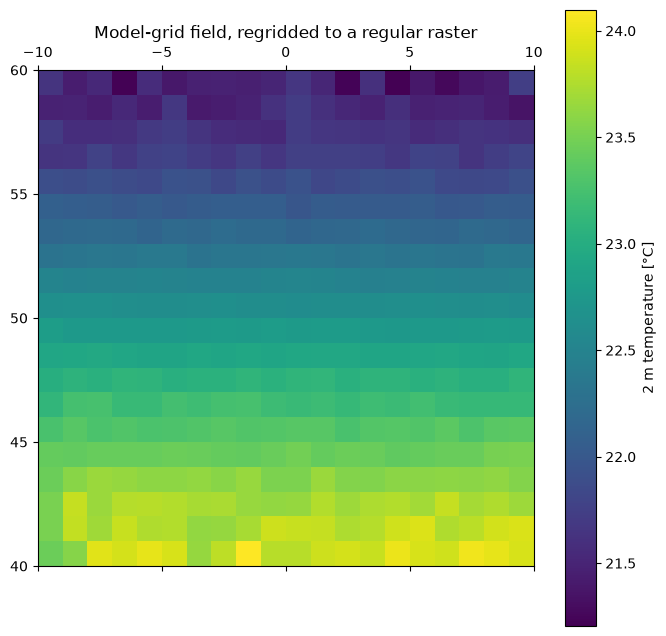

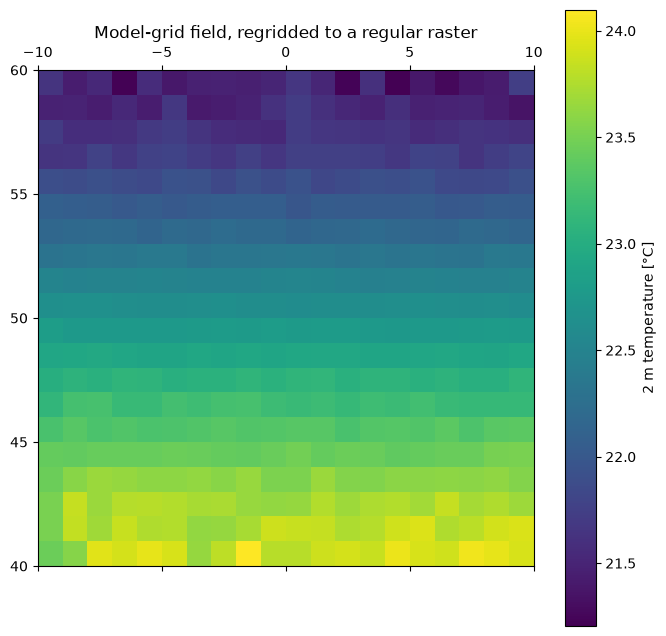

In [3]:
canvas = Map(crs=4326)
canvas.field(field).colorbar(label="2 m temperature [°C]")
canvas.ax.set_title("Model-grid field, regridded to a regular raster")
canvas.fig

## Takeaway

Exotic model grids reach digitalearth already regridded to a regular `Dataset`, so:

```python
from earthlens.grids import from_healpix   # your acquisition step (earthlens, not a digitalearth dep)

ds = from_healpix(values, nside=64, nest=True)   # -> a regular pyramids Dataset
Map(crs=4326).field(ds).colorbar()               # digitalearth renders it unchanged
```

A whole forecast stack lays out the same way with `quickpanels(stack, titles_from="valid_time")` — one
panel per step, each titled by its own metadata.